# 05 - Second-order linear equations: the Wronskian and Abel's theorem

**MATH 331 - Differential Equations.** Unit U5, Sessions 9-11: second-order linear equations,
superposition, existence and uniqueness, linear independence, **the Wronskian**, **Abel's
theorem**, reduction of order. This notebook prepares notebook 06 (characteristic equation) and
notebook 07 (the mass-spring-damper system).

**Sources used to compile this notebook** (full list in Section 10)
* [L] J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`), **Section 2.1**
  (Theorems 2.1.1-2.1.3, the example $y'' - 2x^{-2}y = 0$, reduction of order) and **Section 2.3**
  (Example 2.3.1: $e^x, e^{2x}, e^{3x}$ are independent; Example 2.3.3).
* [AD] W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012):
  **Sect. 3.2** (Wronskian, Example 12), **Sect. 3.3, Theorem 8** (Abel's formula, constant
  coefficients, with proof), **Sect. 4.2, Theorem 6** ($n$-th order Abel formula),
  **Sect. 5.2, Theorem 5 and Example 7** (Abel for variable coefficients; $\cos\ln t$, $\sin\ln t$).
* [AWH] G.B. Arfken, H.J. Weber, F.E. Harris, *Mathematical Methods for Physicists*, 7th ed.
  (Academic Press, 2013), **Section 7.6**: Wronskian and linear dependence (Examples 7.6.1-7.6.2),
  "a second-order ODE has at most two independent solutions" (eqs. 7.56-7.57),
  $W' = -PW$ (eqs. 7.60-7.63, footnote 7), second solution by a double integral (eq. 7.67).
* [DLMF] NIST *Digital Library of Mathematical Functions*, https://dlmf.nist.gov,
  eq. **9.2.7** ($\mathscr W\{\mathrm{Ai},\mathrm{Bi}\} = 1/\pi$) and eq. **10.5.2**
  ($\mathscr W\{J_\nu, Y_\nu\} = 2/(\pi x)$).

**What you will learn (in increasing order of difficulty)**
1. Why a second-order linear homogeneous equation has a **two-dimensional** space of solutions.
2. What the **Wronskian** is, and four ways to look at it: algebraic (a determinant that decides
   whether initial conditions can be met), geometric (an area in the phase plane), through the
   ratio $y_2/y_1$, and through the Vandermonde determinant of exponentials.
3. **Abel's theorem**: the Wronskian of two solutions obeys its own first-order ODE, so it can be
   computed **without solving the equation**, and it is either never zero or identically zero.
4. Two consequences: a formula for a **second solution** (reduction of order) and the
   **Sturm separation theorem** (zeros of independent solutions interlace).

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                     # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. Second-order linear equations: the setting

A second-order **linear** equation in standard form (leading coefficient 1) is

$$
L[y] \;:=\; y'' + p(x)\,y' + q(x)\,y \;=\; f(x).
$$

It is **homogeneous** when $f \equiv 0$. If the equation is written $a(x)y'' + b(x)y' + c(x)y = 0$,
divide by $a(x)$ first (on an interval where $a \neq 0$): $p = b/a$, $q = c/a$. This is important for
Abel's theorem, where the *normalized* coefficient $p$ appears.

$L$ is a **linear operator**: $L[C_1y_1 + C_2y_2] = C_1L[y_1] + C_2L[y_2]$, because
differentiation is linear. Two theorems from [L, Section 2.1] are the foundation of everything that follows.

> **Theorem 2.1.1 (Superposition).** If $y_1, y_2$ solve $L[y] = 0$, so does $C_1y_1 + C_2y_2$ for
> any constants $C_1, C_2$.
>
> **Theorem 2.1.2 (Existence and uniqueness).** If $p, q, f$ are continuous on an interval $I$
> containing $a$, then for every $b_0, b_1$ there is **exactly one** solution on all of $I$ with
> $y(a) = b_0$, $y'(a) = b_1$.

**Running example** [L, Section 2.1]: $\;y'' - \dfrac{2}{x^2}\,y = 0$ on $x > 0$, with solutions
$y_1 = x^2$ and $y_2 = 1/x$. We let SymPy check them, and check superposition.

In [2]:
x = sp.symbols("x", positive=True)                 # work on the interval x > 0
C1, C2 = sp.symbols("C1 C2")

def L_lebl(y):
    """The operator L[y] = y'' - 2 y / x^2 of Lebl's example (applied to a SymPy expression)."""
    return sp.simplify(sp.diff(y, x, 2) - 2 * y / x**2)

y1, y2 = x**2, 1 / x
print("L[x^2]        =", L_lebl(y1))
print("L[1/x]        =", L_lebl(y2))
print("L[C1 y1+C2 y2] =", L_lebl(C1 * y1 + C2 * y2))   # superposition: still zero

L[x^2]        = 0
L[1/x]        = 0
L[C1 y1+C2 y2] = 0


## 2. The question: do two solutions give *all* solutions?

Take two solutions $y_1, y_2$ and try to meet **arbitrary** initial conditions at $x_0$ with
$y = C_1y_1 + C_2y_2$:

$$
\begin{aligned}
C_1\,y_1(x_0) + C_2\,y_2(x_0) &= b_0,\\
C_1\,y_1'(x_0) + C_2\,y_2'(x_0) &= b_1,
\end{aligned}
\qquad\Longleftrightarrow\qquad
\underbrace{\begin{pmatrix} y_1(x_0) & y_2(x_0)\\ y_1'(x_0) & y_2'(x_0)\end{pmatrix}}_{\text{Wronskian matrix}}
\begin{pmatrix} C_1\\ C_2\end{pmatrix} = \begin{pmatrix} b_0\\ b_1\end{pmatrix}.
$$

A $2\times 2$ linear system has a unique solution for **every** right-hand side if and only if its
determinant is nonzero. That determinant is the **Wronskian**:

$$
\boxed{\;W[y_1, y_2](x) \;=\; \det\begin{pmatrix} y_1 & y_2\\ y_1' & y_2'\end{pmatrix} \;=\; y_1\,y_2' - y_1'\,y_2\;}
$$

**Interpretation 1 (algebraic).** $W(x_0) \neq 0$ means *"with $y_1$ and $y_2$ I can match any
initial position and any initial velocity at $x_0$"*. By Cramer's rule

$$
C_1 = \frac{b_0\,y_2'(x_0) - b_1\,y_2(x_0)}{W(x_0)}, \qquad C_2 = \frac{b_1\,y_1(x_0) - b_0\,y_1'(x_0)}{W(x_0)}.
$$

**Theorem (the solution space has dimension 2).** If $W(x_0) \neq 0$ for one $x_0$, then
**every** solution is $y = C_1y_1 + C_2y_2$ [L, Theorem 2.1.3].

*Proof.* Let $y$ be any solution. Choose $C_1, C_2$ by Cramer's rule so that
$z = C_1y_1 + C_2y_2$ has $z(x_0) = y(x_0)$ and $z'(x_0) = y'(x_0)$. Then $y$ and $z$ solve the same
IVP; by uniqueness (Theorem 2.1.2) $y \equiv z$. $\square$

Let us see the system at work on the running example, at $x_0 = 1$.

In [3]:
b0, b1 = sp.symbols("b0 b1")
x0 = 1

# The Wronskian, by hand (definition) and with SymPy's built-in function
W_hand = sp.simplify(y1 * sp.diff(y2, x) - sp.diff(y1, x) * y2)
W_sympy = sp.simplify(sp.wronskian([y1, y2], x))
print("W[x^2, 1/x] =", W_hand, "(by hand) =", W_sympy, "(sympy.wronskian)")   # -3: never zero

# Solve the 2x2 system for C1, C2 (any b0, b1): possible because W(1) = -3 != 0
y_gen = C1 * y1 + C2 * y2
sol = sp.solve([sp.Eq(y_gen.subs(x, x0), b0), sp.Eq(sp.diff(y_gen, x).subs(x, x0), b1)], [C1, C2])
display(Math(r"C_1 = " + sp.latex(sol[C1]) + r",\qquad C_2 = " + sp.latex(sol[C2])))

# A BAD pair: x^2 and 3x^2 are both solutions, but proportional -> W = 0 -> no solution in general
bad = C1 * x**2 + C2 * 3 * x**2
print("W[x^2, 3x^2] =", sp.wronskian([x**2, 3 * x**2], x))
print("solve for y(1)=b0, y'(1)=b1:", sp.solve([sp.Eq(bad.subs(x, 1), b0),
                                               sp.Eq(sp.diff(bad, x).subs(x, 1), b1)], [C1, C2]))

W[x^2, 1/x] = -3 (by hand) = -3 (sympy.wronskian)


<IPython.core.display.Math object>

W[x^2, 3x^2] = 0
solve for y(1)=b0, y'(1)=b1: []


The empty list `[]` means *no* $C_1, C_2$ exist for general $b_0, b_1$: with $x^2$ and $3x^2$ you
can only reach initial data with $b_1 = 2b_0$ (a single line of the $(b_0, b_1)$-plane, not the
whole plane).

## 3. More ways of looking at the Wronskian

### 3.1 Geometric: an area in the phase plane

At each $x$, a solution is described by its **state** $(y, y')$, a point of the phase plane (the
initial conditions are exactly a state). The Wronskian is the determinant of the two state vectors

$$
\mathbf u_1(x) = \begin{pmatrix} y_1\\ y_1'\end{pmatrix}, \qquad \mathbf u_2(x) = \begin{pmatrix} y_2\\ y_2'\end{pmatrix},
$$

that is, the **signed area of the parallelogram** they span (positive when turning from
$\mathbf u_1$ to $\mathbf u_2$ is counter-clockwise).

* $W \neq 0$: the two vectors are not parallel, they span the plane, so **every** initial state
  is a combination of them (this is Section 2, said with pictures).
* $W = 0$: the vectors are parallel, the parallelogram is flat; only states along one line are reachable.

The figure below follows the parallelogram as $x$ moves, for $y'' + 2\zeta y' + y = 0$ with
$y_1(0) = 1, y_1'(0) = 0$ and $y_2(0) = 0, y_2'(0) = 1$ (so $W(0) = 1$). Watch how the shape changes
while the vectors rotate. **Without damping ($\zeta = 0$) the area is constant; with damping it
shrinks.** This is not a coincidence: it is Abel's theorem (Section 5), which predicts
$W(x) = e^{-2\zeta x}$.

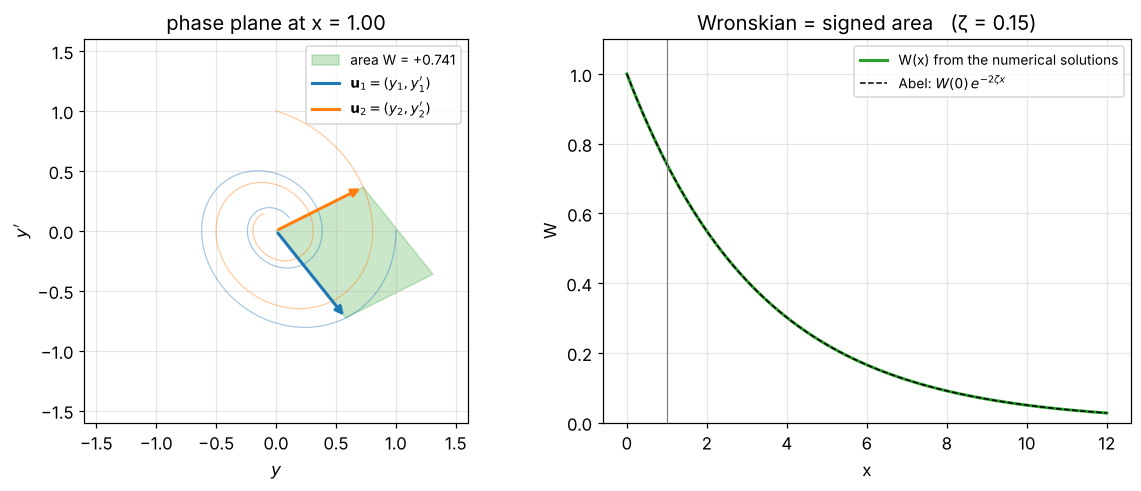

In [4]:
def two_solutions(zeta, xs):
    """Basis y1 (y1(0)=1, y1'(0)=0) and y2 (y2(0)=0, y2'(0)=1) of y'' + 2 zeta y' + y = 0, with derivatives.

    Computed with RK4 on the first-order system (y, y')' = (y', -2 zeta y' - y), applied to both
    solutions at once (4 unknowns). Using a numerical solver on purpose: the picture does not rely
    on knowing formulas for the solutions.
    """
    rhs = lambda t, u: np.array([u[1], -2 * zeta * u[1] - u[0], u[3], -2 * zeta * u[3] - u[2]])  # noqa: E731
    t, u = ol.rk4(rhs, (xs[0], xs[-1]), [1.0, 0.0, 0.0, 1.0], xs[1] - xs[0])
    return t, u[:, 0], u[:, 1], u[:, 2], u[:, 3]         # x, y1, y1', y2, y2'


def plot_parallelogram(x_now=1.0, zeta=0.15):
    xs = np.linspace(0, 12, 2401)                        # step 0.005, a whole number of steps
    t, a, da, b, db = two_solutions(zeta, xs)
    i = np.searchsorted(t, x_now)                        # index of the current x
    W = ol.wronskian_values(a, da, b, db)                # signed area, at every x

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))
    # left: phase plane with the two state vectors and their parallelogram
    ax1.plot(a, da, color="tab:blue", lw=0.8, alpha=0.4)              # path of u1 = (y1, y1')
    ax1.plot(b, db, color="tab:orange", lw=0.8, alpha=0.4)            # path of u2 = (y2, y2')
    u1, u2 = np.array([a[i], da[i]]), np.array([b[i], db[i]])
    corners = np.array([[0, 0], u1, u1 + u2, u2])
    ax1.fill(corners[:, 0], corners[:, 1], color="tab:green", alpha=0.25, label=f"area W = {W[i]:+.3f}")
    labels = (r"$\mathbf{u}_1=(y_1,y_1')$", r"$\mathbf{u}_2=(y_2,y_2')$")
    for u, c, name in ((u1, "tab:blue", labels[0]), (u2, "tab:orange", labels[1])):
        ax1.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2))
        ax1.plot([], [], color=c, lw=2, label=name)                     # legend entry for the arrow
    ax1.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal", xlabel="$y$", ylabel="$y'$",
            title=f"phase plane at x = {t[i]:.2f}")
    ax1.legend(loc="upper right")
    # right: the area as a function of x, compared with Abel's prediction e^{-2 zeta x}
    ax2.plot(t, W, color="tab:green", lw=2, label="W(x) from the numerical solutions")
    ax2.plot(t, np.exp(-2 * zeta * t), "k--", lw=1, label=r"Abel: $W(0)\,e^{-2\zeta x}$")
    ax2.axvline(t[i], color="gray", lw=0.8)
    ax2.set(xlabel="x", ylabel="W", ylim=(0, 1.1), title=f"Wronskian = signed area   (ζ = {zeta})")
    ax2.legend()
    plt.tight_layout()
    plt.show()


plot_parallelogram(x_now=1.0, zeta=0.15)                 # static figure (visible without a kernel)

In [5]:
# Interactive version: move x and the damping zeta. The vectors rotate and stretch, but the area
# follows e^{-2 zeta x} exactly - it never depends on WHERE the vectors are, only on x.
interact(plot_parallelogram,
         x_now=FloatSlider(value=1.0, min=0, max=12, step=0.1, description="x", continuous_update=False),
         zeta=FloatSlider(value=0.15, min=0, max=0.5, step=0.05, description="ζ", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='x', max=12.0), FloatSlider(…

### 3.2 Through the ratio $y_2/y_1$

Where $y_1 \neq 0$, the quotient rule gives

$$
\left(\frac{y_2}{y_1}\right)' = \frac{y_1y_2' - y_1'y_2}{y_1^2} = \frac{W}{y_1^2}.
$$

So **$W \equiv 0$ on an interval (where $y_1 \neq 0$) exactly when $y_2/y_1$ is constant**, i.e.
when one function is a multiple of the other. This is the elementary definition of linear
dependence for two functions [L, Section 2.1]: the Wronskian measures *how fast the ratio
changes*. Lebl checks $x^2$ and $1/x$ with the ratio $y_1/y_2 = x^3$, "most decidedly not a constant".

The same formula, read backwards, will give a second solution from a first one (Section 6).

### 3.3 For exponentials: the Vandermonde determinant

For $y_k = e^{r_kx}$ the $k$-th derivative of $e^{rx}$ is $r^ke^{rx}$, so every column of the
Wronskian matrix carries a factor $e^{r_kx}$ that can be pulled out:

$$
W[e^{r_1x},\dots,e^{r_nx}] = e^{(r_1+\dots+r_n)x}\,
\det\begin{pmatrix}1 & \cdots & 1\\ r_1 & \cdots & r_n\\ \vdots & & \vdots\\ r_1^{n-1} & \cdots & r_n^{n-1}\end{pmatrix}
= e^{(r_1+\dots+r_n)x}\prod_{i<j}(r_j - r_i).
$$

The last determinant is the classical **Vandermonde determinant**. Conclusion: **exponentials
with distinct rates are always linearly independent**. For $n = 2$: $W = (r_2 - r_1)e^{(r_1+r_2)x}$,
the key formula of notebook 06. Lebl's Example 2.3.1 shows by three *other* methods that
$e^x, e^{2x}, e^{3x}$ are independent; here is the Wronskian way: $W = (2-1)(3-1)(3-2)\,e^{6x} = 2e^{6x}$.

In [6]:
r = sp.symbols("r1:4")                                    # three symbolic rates r1, r2, r3
exps = [sp.exp(rk * x) for rk in r]
W3 = sp.factor(sp.simplify(sp.wronskian(exps, x)))
display(Math(r"W[e^{r_1x},e^{r_2x},e^{r_3x}] = " + sp.latex(W3)))

# Lebl, Example 2.3.1: e^x, e^{2x}, e^{3x}
print("W[e^x, e^2x, e^3x] =", sp.simplify(sp.wronskian([sp.exp(x), sp.exp(2 * x), sp.exp(3 * x)], x)))
# Arfken, Example 7.6.2: e^x, e^-x, cosh x are DEPENDENT (e^x + e^-x - 2 cosh x = 0) -> W = 0
print("W[e^x, e^-x, cosh x] =", sp.simplify(sp.wronskian([sp.exp(x), sp.exp(-x), sp.cosh(x)], x)))

<IPython.core.display.Math object>

W[e^x, e^2x, e^3x] = 2*exp(6*x)
W[e^x, e^-x, cosh x] = 0


## 4. A warning: the Wronskian test only works one way for arbitrary functions

For **any** differentiable functions: *if $W(x_0) \neq 0$ at some point, then $f_1, f_2$ are
linearly independent* [AD, Sect. 3.2; AWH, Section 7.6]. (If $C_1f_1 + C_2f_2 \equiv 0$, differentiate:
$(C_1, C_2)$ solves the homogeneous system with matrix $W$, so $W \equiv 0$.)

**The converse is false** for arbitrary functions. Classic counterexample: $f_1 = t^3$,
$f_2 = |t|^3$. Both are continuously differentiable, $W \equiv 0$ on $\mathbb R$, but they are
**independent** on $(-1, 1)$: $f_2 = f_1$ for $t > 0$ and $f_2 = -f_1$ for $t < 0$, so no single
constant works. Also, $W$ of arbitrary functions may vanish at isolated points:
$W[t, t^2] = t^2$ is zero only at $t = 0$.

[AD, Sect. 3.2] warns: *"If the Wronskian is zero, you cannot conclude"* dependence. The next
section shows that **for solutions of one linear equation, these pathologies cannot happen**.

W[t^3, |t|^3] = 0  (check at a few points: [0, 0, 0, 0] )
W[t, t^2] = t**2
Adkins Sect. 3.2, Example 12:  W[t, 1/t] = -2/t   W[e^2t, e^t] = -exp(3*t)


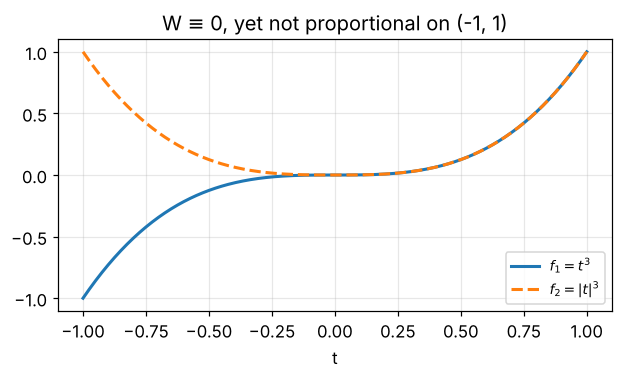

In [7]:
t = sp.symbols("t", real=True)
f1, f2 = t**3, sp.Abs(t)**3
W_t = sp.simplify(f1 * sp.diff(f2, t) - sp.diff(f1, t) * f2)
print("W[t^3, |t|^3] =", W_t, " (check at a few points:",
      [W_t.subs(t, v) for v in (-2, -0.5, 0.5, 2)], ")")
print("W[t, t^2] =", sp.wronskian([t, t**2], t))
print("Adkins Sect. 3.2, Example 12:  W[t, 1/t] =", sp.simplify(sp.wronskian([t, 1 / t], t)),
      "  W[e^2t, e^t] =", sp.simplify(sp.wronskian([sp.exp(2 * t), sp.exp(t)], t)))

tt = np.linspace(-1, 1, 401)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(tt, tt**3, lw=2, label="$f_1 = t^3$")
ax.plot(tt, np.abs(tt)**3, "--", lw=2, label="$f_2 = |t|^3$")
ax.set(xlabel="t", title="W ≡ 0, yet not proportional on (-1, 1)")
ax.legend()
plt.show()

Why can't $t^3$ and $|t|^3$ both solve some $y'' + p(t)y' + q(t)y = 0$ with continuous $p, q$?
At $t = 0$ both have $y = y' = 0$; by **uniqueness** the only such solution is $y \equiv 0$. That is
exactly the argument of the next section.

## 5. Abel's theorem

> **Theorem (Abel's formula)** [AD, Sect. 3.3 Thm 8 and Sect. 5.2 Thm 5; AWH, eq. 7.63].
> Let $p, q$ be continuous on an interval $I$, and let $y_1, y_2$ be solutions of
> $y'' + p(x)y' + q(x)y = 0$ on $I$. Then for any $x_0 \in I$
> $$
> \boxed{\;W(x) = W(x_0)\,\exp\!\left(-\int_{x_0}^{x} p(s)\,ds\right)\;}
> $$
> Consequently **either $W(x) \neq 0$ for every $x \in I$, or $W \equiv 0$ on $I$**; and $y_1, y_2$
> are linearly independent **if and only if** $W \neq 0$.

**Proof** (three lines, worth remembering). Differentiate $W = y_1y_2' - y_1'y_2$; the terms
$y_1'y_2'$ cancel:

$$
W' = y_1'y_2' + y_1y_2'' - y_1''y_2 - y_1'y_2' = y_1y_2'' - y_1''y_2.
$$

Substitute $y_k'' = -p\,y_k' - q\,y_k$; the $q$-terms cancel too:

$$
W' = y_1(-py_2' - qy_2) - (-py_1' - qy_1)y_2 = -p\,(y_1y_2' - y_1'y_2) = -p\,W.
$$

So $W$ solves the **first-order linear** equation $W' = -p(x)\,W$ (notebook 02's decay
equation, with a variable rate!), whose solution is the boxed formula. The exponential is never zero,
so $W$ vanishes either nowhere or everywhere.

Independence $\Rightarrow W \neq 0$: suppose instead $W \equiv 0$. If $y_1 \equiv y_2 \equiv 0$ the pair
is trivially dependent; otherwise pick $x_0$ where $y_1(x_0)$ or $y_2(x_0)$ is nonzero and set
$z = y_2(x_0)\,y_1 - y_1(x_0)\,y_2$, a solution by superposition. Then $z(x_0) = 0$ and
$z'(x_0) = y_2(x_0)y_1'(x_0) - y_1(x_0)y_2'(x_0) = -W(x_0) = 0$, so $z \equiv 0$ by uniqueness: a
dependence relation with coefficients not both zero [AD, proof of Thm 8]. The converse
($W \neq 0 \Rightarrow$ independence) was shown in Section 4. $\square$

**Why this matters.**
1. **No pathologies for solutions.** The $t^3, |t|^3$ example of Section 4 cannot occur: for
   solutions, checking $W$ at **one** point decides independence on the whole interval.
2. **$W$ without solving.** The Wronskian depends only on $p$ and one number $W(x_0)$, even when
   we cannot find $y_1, y_2$ in closed form (Airy, Bessel below).
3. **Physics: phase-space volume.** In Section 3.1, $W$ is an area. Abel says the area changes at
   the relative rate $-p$. With $p = 0$ (no first-derivative term, no friction) **areas are
   conserved**, the simplest instance of Liouville's theorem of mechanics. With damping
   $p = c/m > 0$, areas contract (notebook 07).
4. **Constant coefficients.** For $ay'' + by' + cy = 0$, $p = b/a$, so $W = K\,e^{-bx/a}$
   [AD, Remark 9]. In notebook 06 we will see the same result from the roots of the
   characteristic equation (via $r_1 + r_2 = -b/a$).

In [8]:
# Abel at work: compare W computed from KNOWN solutions with the prediction W(x0) exp(-int p).
s = sp.symbols("s")

def abel_check(name, p, sols, var, x0):
    """Print W from the solutions and from Abel's formula; they must agree."""
    W_direct = sp.simplify(sp.wronskian(sols, var))
    W_abel = sp.simplify(W_direct.subs(var, x0) * sp.exp(-sp.integrate(p.subs(var, s), (s, x0, var))))
    ok = sp.simplify(W_direct - W_abel) == 0
    display(Math(rf"\text{{{name}}}:\quad p = {sp.latex(p)},\quad W = {sp.latex(W_direct)},"
                 rf"\quad W(x_0)e^{{-\int p}} = {sp.latex(W_abel)}\quad"
                 + (r"\checkmark" if ok else r"\times")))

w = sp.symbols("omega", positive=True)
abel_check("Lebl 2.1: y'' - 2y/x^2 = 0", sp.Integer(0), [x**2, 1 / x], x, 1)
abel_check("Arfken Ex. 7.6.1: y'' + w^2 y = 0", sp.Integer(0), [sp.sin(w * x), sp.cos(w * x)], x, 0)
# Adkins Sect. 5.2 Example 7: t^2 y'' + t y' + y = 0 -> divide by t^2: p = 1/t
tp = sp.symbols("t", positive=True)
abel_check("Adkins 5.2 Ex. 7: t^2 y'' + t y' + y = 0", 1 / tp,
           [sp.cos(sp.log(tp)), sp.sin(sp.log(tp))], tp, 1)
# A damped oscillator y'' + 2y' + 5y = 0 (roots -1 +- 2i): p = 2 -> W ~ e^{-2x}
abel_check("y'' + 2y' + 5y = 0", sp.Integer(2),
           [sp.exp(-x) * sp.cos(2 * x), sp.exp(-x) * sp.sin(2 * x)], x, 0)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 5.1 Abel for functions we cannot write down: Airy and Bessel

The **Airy equation** $y'' - xy = 0$ (optics, quantum tunnelling) has no elementary solutions; its
standard solutions $\mathrm{Ai}, \mathrm{Bi}$ are special functions. Here $p = 0$, so Abel says
$W[\mathrm{Ai},\mathrm{Bi}]$ is **constant**; DLMF 9.2.7 gives the constant: $1/\pi$.

**Bessel's equation** $x^2y'' + xy' + (x^2 - \nu^2)y = 0$ (vibrating drums, heat in cylinders):
dividing by $x^2$, $p = 1/x$, so $W = K\exp(-\ln x) = K/x$. DLMF 10.5.2: $W[J_\nu, Y_\nu] = 2/(\pi x)$.

We check both with SciPy's implementations of these functions: Abel's prediction is a
**constant** for Airy and a **$1/x$ law** for Bessel, whatever $\nu$.

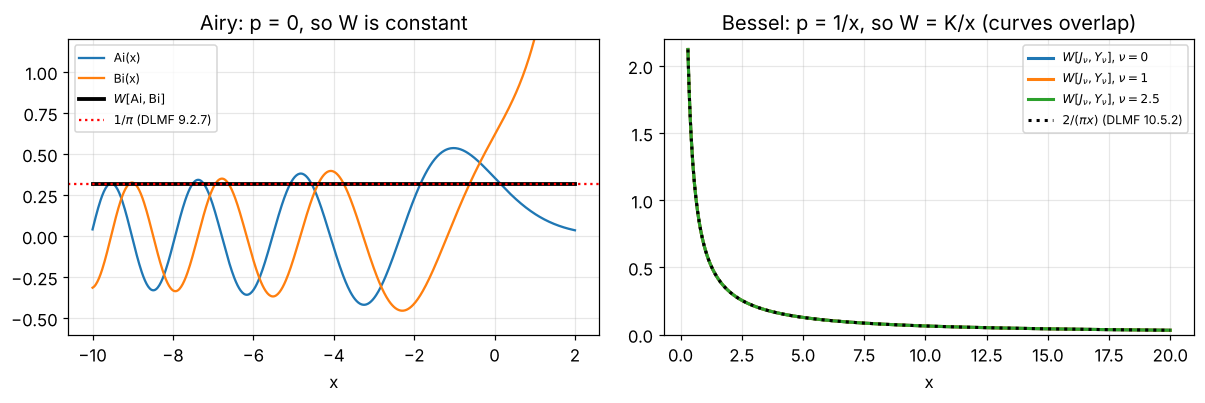

max |W_airy - 1/pi| = 2.609024107869118e-15


In [9]:
from scipy.special import airy, jv, jvp, yv, yvp       # special functions and their derivatives

xa = np.linspace(-10, 2, 600)
ai, aip, bi, bip = airy(xa)                             # Ai, Ai', Bi, Bi'
W_airy = ol.wronskian_values(ai, aip, bi, bip)

xb = np.linspace(0.3, 20, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(xa, ai, label="Ai(x)")
ax1.plot(xa, bi, label="Bi(x)")
ax1.plot(xa, W_airy, "k", lw=2.5, label=r"$W[\mathrm{Ai},\mathrm{Bi}]$")
ax1.axhline(1 / np.pi, color="red", ls=":", label=r"$1/\pi$ (DLMF 9.2.7)")
ax1.set(ylim=(-0.6, 1.2), xlabel="x", title="Airy: p = 0, so W is constant")
ax1.legend(fontsize=8)
for nu in (0, 1, 2.5):
    W_b = ol.wronskian_values(jv(nu, xb), jvp(nu, xb), yv(nu, xb), yvp(nu, xb))
    ax2.plot(xb, W_b, lw=2, label=fr"$W[J_\nu,Y_\nu]$, $\nu={nu}$")
ax2.plot(xb, 2 / (np.pi * xb), "k:", lw=2, label=r"$2/(\pi x)$ (DLMF 10.5.2)")
ax2.set(xlabel="x", ylim=(0, 2.2), title="Bessel: p = 1/x, so W = K/x (curves overlap)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("max |W_airy - 1/pi| =", np.max(np.abs(W_airy - 1 / np.pi)))

### 5.2 What if $p$ is not continuous?

Abel's theorem needs $p$ continuous on the interval. Arfken's footnote 7 [AWH, Section 7.6]: *if
$P(x)$ does not remain finite, $W$ can have isolated zeros*. Example:
$y'' - \dfrac{2}{x}y' + \dfrac{2}{x^2}y = 0$ has solutions $x$ and $x^2$, with $W = x^2$, which is
zero at $x = 0$, exactly where $p = -2/x$ blows up. On $(0, \infty)$ and on $(-\infty, 0)$ separately,
$W \neq 0$, as Abel says ($W = Kx^2$).

### 5.3 Numerical check with a variable coefficient

Finally, a case where we know neither solution: $y'' + \dfrac{1}{1+x}y' + y = 0$. Abel predicts
$W(x) = W(0)/(1+x)$. We integrate two solutions numerically (RK4), compute $W$ from them, and
compare with the prediction. The slider changes the strength $\alpha$ of the coefficient
$p = \alpha/(1+x)$; then Abel gives $W = W(0)\,(1+x)^{-\alpha}$.

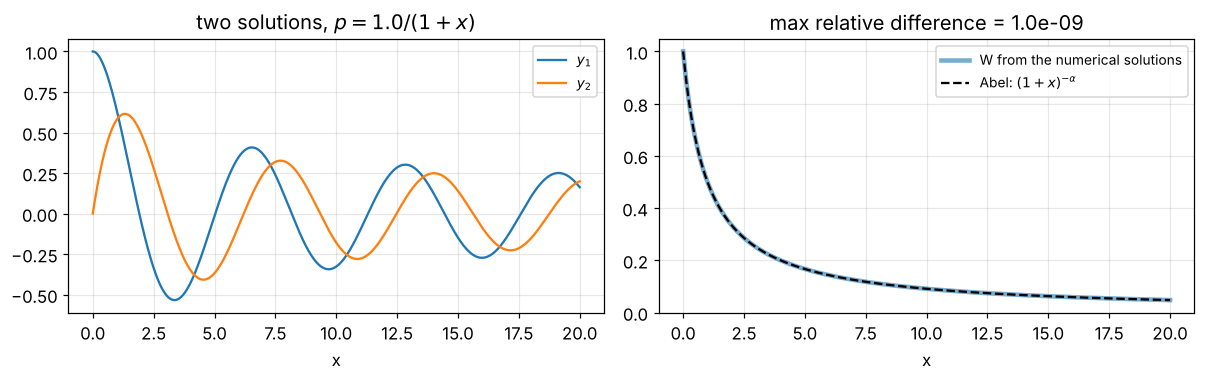

In [10]:
def abel_numeric(alpha=1.0, x_end=20.0):
    """Integrate two solutions of y'' + alpha/(1+x) y' + y = 0 and compare W with Abel's formula."""
    def rhs(x, u):                                       # u = (y1, y1', y2, y2')
        p = alpha / (1 + x)
        return np.array([u[1], -p * u[1] - u[0], u[3], -p * u[3] - u[2]])
    xs, u = ol.rk4(rhs, (0, x_end), [1.0, 0.0, 0.0, 1.0], 0.01)   # W(0) = 1*1 - 0*0 = 1
    W_num = ol.wronskian_values(u[:, 0], u[:, 1], u[:, 2], u[:, 3])
    W_abel = (1 + xs) ** (-alpha)                        # exp(-int_0^x alpha/(1+s) ds)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    ax1.plot(xs, u[:, 0], label="$y_1$")
    ax1.plot(xs, u[:, 2], label="$y_2$")
    ax1.set(xlabel="x", title=fr"two solutions, $p = {alpha}/(1+x)$")
    ax1.legend()
    ax2.plot(xs, W_num, lw=3, alpha=0.6, label="W from the numerical solutions")
    ax2.plot(xs, W_abel, "k--", label=r"Abel: $(1+x)^{-\alpha}$")
    ax2.set(xlabel="x", title=f"max relative difference = {np.max(np.abs(W_num / W_abel - 1)):.1e}")
    ax2.legend()
    plt.tight_layout()
    plt.show()


abel_numeric(alpha=1.0)

In [11]:
interact(abel_numeric,
         alpha=FloatSlider(value=1.0, min=-1.0, max=3.0, step=0.25, description="α",
                           continuous_update=False),
         x_end=FloatSlider(value=20, min=5, max=40, step=5, description="x max", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='α', max=3.0, min=-1.0, step…

With $\alpha < 0$ the "friction" is negative (energy is pumped in) and $W$ **grows**: Abel's
formula works for either sign of $p$.

## 6. Consequences of Abel's theorem

### 6.1 At most two independent solutions [AWH, eqs. 7.56-7.57]

Suppose $y_1, y_2, y_3$ all solve $y'' + py' + qy = 0$. Expand the $3\times 3$ Wronskian along its
second row: each $2\times 2$ minor $W_{jk}$ satisfies $W_{jk}' = -pW_{jk}$ (Abel), and reassembling,
$W[y_1,y_2,y_3] = -p\cdot(\text{a determinant with two equal rows}) = 0$. So **three solutions
are always dependent**: the solution space has dimension exactly 2.

### 6.2 A second solution from a first one (reduction of order)

If $y_1$ is known, combine Section 3.2 with Abel: $(y_2/y_1)' = W/y_1^2$ and $W = e^{-\int p}$
(choosing $W(x_0) = 1$). Integrating,

$$
\boxed{\;y_2(x) = y_1(x)\int^x \frac{e^{-\int^{s} p(\sigma)\,d\sigma}}{y_1(s)^2}\,ds\;}
\qquad \text{[L, Section 2.1; AWH, eq. 7.67]}
$$

Two examples:
* **Repeated root** (preview of notebook 06): $y'' - 2ry' + r^2y = 0$ has $y_1 = e^{rx}$, $p = -2r$:
  $y_2 = e^{rx}\int e^{2rx}/e^{2rx}\,dx = x\,e^{rx}$.
* **Legendre's equation with $n = 1$**: $(1 - x^2)y'' - 2xy' + 2y = 0$ has $y_1 = x$. On
  $(-1, 1)$, $p = -2x/(1-x^2)$, $e^{-\int p} = 1/(1-x^2)$, and the formula produces the
  Legendre function of the second kind $Q_1(x) = \frac{x}{2}\ln\frac{1+x}{1-x} - 1$.

In [12]:
def second_solution(y1, p, var):
    """Reduction of order: y2 = y1 * integral( exp(-integral p) / y1^2 ), constants of integration omitted."""
    W = sp.exp(-sp.integrate(p, var))                    # Abel, with the constant chosen as 1
    return sp.simplify(y1 * sp.integrate(sp.simplify(W / y1**2), var))

rr = sp.symbols("r", real=True)
print("repeated root:  y2 =", second_solution(sp.exp(rr * x), -2 * rr, x))

# Legendre n = 1 on (-1, 1). Abel: W = exp(-int p) = 1/(1 - x^2). SymPy writes the antiderivative of
# W / y1^2 with logarithms of negative numbers, so we give the real one on (-1, 1) and CHECK it.
xl = sp.symbols("x")
W_leg = 1 / (1 - xl**2)
F = -1 / xl + sp.atanh(xl)                               # candidate antiderivative of W / x^2
print("F' - W/x^2 =", sp.simplify(sp.diff(F, xl) - W_leg / xl**2))
y2_leg = sp.expand(xl * F)                               # y2 = y1 * F = x artanh(x) - 1 = Q_1(x)
print("Legendre n = 1: y2 =", y2_leg)
residual = sp.simplify((1 - xl**2) * sp.diff(y2_leg, xl, 2) - 2 * xl * sp.diff(y2_leg, xl) + 2 * y2_leg)
print("check: (1-x^2) y2'' - 2x y2' + 2 y2 =", residual)

repeated root:  y2 = x*exp(r*x)
F' - W/x^2 = 0
Legendre n = 1: y2 = x*atanh(x) - 1
check: (1-x^2) y2'' - 2x y2' + 2 y2 = 0


Since $\operatorname{artanh} x = \frac12\ln\frac{1+x}{1-x}$, we found
$y_2 = x\operatorname{artanh}x - 1 = Q_1(x)$, exactly the Legendre function of the second kind.

### 6.3 The Sturm separation theorem: zeros interlace

> **Theorem.** If $y_1, y_2$ are **independent** real solutions of $y'' + py' + qy = 0$ on $I$,
> then between two consecutive zeros of $y_1$ there is **exactly one** zero of $y_2$.

*Proof.* By Abel, $W$ never vanishes, so it has a constant sign on $I$. At a zero $a$ of $y_1$,
$W(a) = -y_1'(a)\,y_2(a)$; hence $y_2(a) \ne 0$ and $y_1'(a) \neq 0$. At two consecutive zeros
$a < b$ of $y_1$, the slopes $y_1'(a), y_1'(b)$ have **opposite** signs (the graph crosses the axis
once going up, once going down). Since $W(a)$ and $W(b)$ have the same sign, $y_2(a)$ and $y_2(b)$
must have opposite signs, so $y_2$ has a zero in $(a, b)$ (intermediate value theorem). Exchanging the
roles of $y_1$ and $y_2$, there cannot be two zeros of $y_2$ there either. $\square$

So sine and cosine "take turns" crossing zero, and the same holds for the Airy functions, whose
zeros are not equally spaced. The slider mixes $\mathrm{Ai}$ and $\mathrm{Bi}$:
$y_\theta = \cos\theta\,\mathrm{Ai} + \sin\theta\,\mathrm{Bi}$ is another solution, independent of
$\mathrm{Ai}$ when $\sin\theta \neq 0$ (its Wronskian with $\mathrm{Ai}$ is $\sin\theta/\pi$).

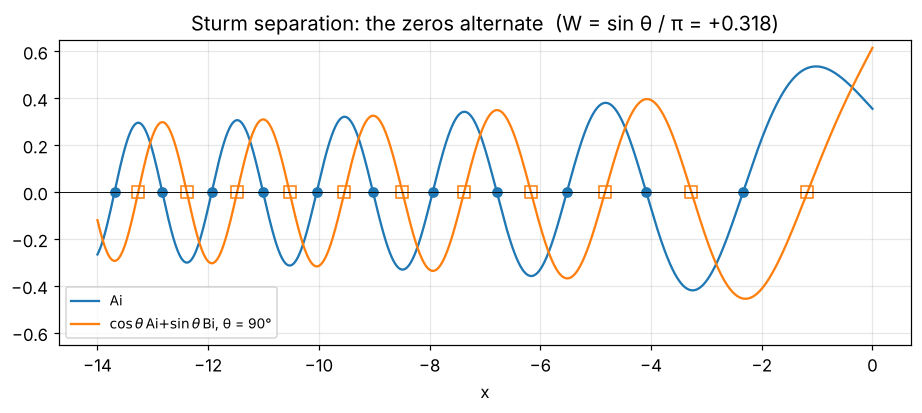

In [13]:
def zeros_of(xs, ys):
    """Zeros of a sampled function, located by sign changes and refined by linear interpolation."""
    k = np.nonzero(np.sign(ys[:-1]) * np.sign(ys[1:]) < 0)[0]
    return xs[k] - ys[k] * (xs[k + 1] - xs[k]) / (ys[k + 1] - ys[k])


def plot_sturm(theta_deg=90.0):
    xs = np.linspace(-14, 0, 4001)
    ai, _, bi, _ = airy(xs)
    th = np.radians(theta_deg)
    y_theta = np.cos(th) * ai + np.sin(th) * bi          # another solution of y'' = x y
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.plot(xs, ai, color="tab:blue", label="Ai")
    label = fr"$\cos\theta\,$Ai$+\sin\theta\,$Bi, θ = {theta_deg:.0f}°"
    ax.plot(xs, y_theta, color="tab:orange", label=label)
    ax.plot(zeros_of(xs, ai), 0 * zeros_of(xs, ai), "o", color="tab:blue")
    ax.plot(zeros_of(xs, y_theta), 0 * zeros_of(xs, y_theta), "s", mfc="none", color="tab:orange", ms=8)
    ax.axhline(0, color="k", lw=0.6)
    ax.set(xlabel="x", ylim=(-0.65, 0.65),
           title=fr"Sturm separation: the zeros alternate  (W = sin θ / π = {np.sin(th) / np.pi:+.3f})")
    ax.legend(loc="lower left")
    plt.show()


plot_sturm(90)

In [14]:
interact(plot_sturm, theta_deg=FloatSlider(value=90, min=0, max=180, step=5, description="θ [deg]",
                                           continuous_update=False));

interactive(children=(FloatSlider(value=90.0, continuous_update=False, description='θ [deg]', max=180.0, step=…

At $\theta = 0°$ and $180°$ the two solutions are proportional ($W = 0$) and the zeros coincide:
the theorem requires **independence**.

## 7. Looking ahead: systems and the $n$-th order case

**First-order systems (Liouville's formula).** Write $y'' + py' + qy = 0$ as $\mathbf u' = A(x)\mathbf u$
with $\mathbf u = (y, y')^T$ and the *companion matrix*
$A = \begin{pmatrix} 0 & 1 \\ -q & -p\end{pmatrix}$. If $\Phi$ is the matrix whose columns are the
states of $y_1, y_2$, then $W = \det\Phi$ and Abel's theorem is the $2\times 2$ case of

$$
\frac{d}{dx}\det\Phi = (\operatorname{tr}A)\,\det\Phi, \qquad \operatorname{tr}A = -p .
$$

This statement (Liouville's formula) holds for any $n\times n$ linear system and will reappear in
the unit on systems (notebook on $\mathbf x' = A\mathbf x$).

**$n$-th order equations** [AD, Sect. 4.2, Thm 6]. For
$y^{(n)} + a_{n-1}(x)y^{(n-1)} + \dots + a_0(x)y = 0$, the Wronskian of $n$ solutions satisfies
$W' = -a_{n-1}W$. Example: Lebl's Example 2.3.3, $y''' - 3y'' - y' + 3y = 0$, has solutions
$e^{3x}, e^x, e^{-x}$ and $a_2 = -3$, so $W = Ke^{3x}$; the Vandermonde formula gives
$K = (1-3)(-1-3)(-1-1) = -16$.

In [15]:
sols3 = [sp.exp(3 * x), sp.exp(x), sp.exp(-x)]
print("residuals of y^(3) - 3y^(2) - y^(1) + 3y:",
      [sp.simplify(sp.diff(f, x, 3) - 3 * sp.diff(f, x, 2) - sp.diff(f, x) + 3 * f) for f in sols3])
print("W =", sp.simplify(sp.wronskian(sols3, x)))          # -16 e^{3x}: proportional to e^{-a2 x}

# Liouville: the trace of the companion matrix is -p
pp, qq = sp.symbols("p q")
A = sp.Matrix([[0, 1], [-qq, -pp]])
print("companion matrix trace:", A.trace())

residuals of y^(3) - 3y^(2) - y^(1) + 3y: [0, 0, 0]
W = -16*exp(3*x)
companion matrix trace: -p


## 8. Summary

| Statement | Formula | Source |
|---|---|---|
| Wronskian | $W = y_1y_2' - y_1'y_2$ | [L 2.1], [AD 3.2], [AWH 7.6] |
| Initial conditions can always be met | $\iff W(x_0) \neq 0$ (Cramer) | [L Thm 2.1.3] |
| Geometric meaning | signed area spanned by $(y_1,y_1')$, $(y_2,y_2')$ | this notebook |
| Ratio | $(y_2/y_1)' = W/y_1^2$ | [L 2.1] |
| Exponentials | $W = e^{(\sum r_k)x}\prod_{i<j}(r_j - r_i)$ | Vandermonde |
| **Abel** | $W(x) = W(x_0)\,e^{-\int_{x_0}^x p}$; never zero or always zero | [AD 3.3, 5.2], [AWH 7.63] |
| Second solution | $y_2 = y_1\int e^{-\int p}/y_1^2$ | [L 2.1], [AWH 7.67] |
| Sturm separation | zeros of independent solutions interlace | consequence of Abel |

## 9. Exercises

1. *(Lebl 2.1)* Verify that $y_1 = x^2$, $y_2 = 1/x$ solve $y'' - 2x^{-2}y = 0$, find the solution
   with $y(1) = 2$, $y'(1) = 1$, and check that $W = -3$ agrees with Abel ($p = 0$).
2. *(Adkins 3.3, Exercises 17-18)* For $\{e^{3t}, e^{7t}\}$ find the polynomial $q(s) = s^2 + bs + c$
   whose equation they solve, compute $W$ and the constant $K$ in $W = Ke^{-bt}$. Repeat for
   $\{e^{r_1t}, e^{r_2t}\}$.
3. Without solving, find $W[y_1, y_2]$ for two solutions of $x\,y'' + 2y' + x\,y = 0$ with
   $W(1) = 1$. Then verify with $y_1 = \sin x / x$, $y_2 = \cos x / x$.
4. *(Arfken, Exercise 7.6.4)* Show that if $W[y_1, y_2] \equiv 0$ on an interval where $y_1 \neq 0$,
   then $y_2 = c\,y_1$. (Hint: Section 3.2.)
5. Explain, with the phase-plane picture of Section 3.1, why for $y'' + q(x)y = 0$ the
   parallelogram may change shape but never its area. What changes if a term $p\,y'$ with $p > 0$
   is added?
6. Use reduction of order to find a second solution of $x^2y'' - 3xy' + 4y = 0$ ($x > 0$) given
   $y_1 = x^2$. *(Answer: $x^2\ln x$.)*
7. Use the Sturm separation theorem to prove that every nonzero solution of $y'' + y = 0$ has
   exactly one zero in every interval $[a, a + \pi)$.

## 10. References

* **[L]** J. Lebl, *Notes on Diffy Qs: Differential Equations for Engineers*,
  `ode/FullText_Diff_Eq_For_Engineers.pdf`, Sections 2.1 and 2.3. (Course textbook.)
* **[AD]** W.A. Adkins, M.G. Davidson, *Ordinary Differential Equations*, Springer UTM (2012),
  Sections 3.2, 3.3, 4.2 and 5.2.
* **[AWH]** G.B. Arfken, H.J. Weber, F.E. Harris, *Mathematical Methods for Physicists*,
  7th ed., Academic Press (2013), Section 7.6, *Other Solutions*.
* **[DLMF]** F.W.J. Olver et al. (eds.), *NIST Digital Library of Mathematical Functions*,
  https://dlmf.nist.gov, eqs. 9.2.7 and 10.5.2.
* The Sturm separation theorem and Liouville's formula are classical; see e.g. [AWH, Ch. 7]
  and the systems chapter of [L] (Chapter 3).